In [39]:
import numpy as np
import matplotlib
%matplotlib inline  
# matplotlib.use("TkAgg")    # or "Qt5Agg" depending on what you have installed
import matplotlib.pyplot as plt
from matplotlib import rcParams
from astropy import units as u
from scipy.stats import norm
import pandas as pd
import scipy.interpolate as si

AU_cm = (1 * u.AU).to(u.cm).value
sol_to_earth = 332946.078

In [40]:
params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [41]:
#Color-blind friendly pallete
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#8B8D8B",  # Medium Grey
    "#5D3A9B"   # Muted Purple
]

vib_blue = "#0C7BDC"
teal = "#40B0A6"
purple = "#5D3A9B" 
dot_scale = 500

In [42]:
ueda_semis = np.loadtxt("/Users/honeyeah/Codes/planet_cookbook/examples/pl_disk_surface_density/ueda_2021_v5.txt")

cham_cont_as = np.loadtxt("/Users/honeyeah/Codes/data/cham_cont/cham_cont_47/cont_semis.txt")
cham_cont_ms = np.loadtxt("/Users/honeyeah/Codes/data/cham_cont/cham_cont_47/cont_masses.txt")
cham_cont_df = pd.DataFrame(columns=['m', 'a'])
cham_cont_df['m'] = cham_cont_ms * sol_to_earth
cham_cont_df['a'] = cham_cont_as

cham_bi_embs = np.loadtxt("/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_3/cham_bimodal_emb_samples_sep3.txt")
cham_bi_pls = np.loadtxt("/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_3/cham_bimodal_pl_samples_sep3.txt")
emb_masses = np.ones(14) * 2.8e-7 * sol_to_earth
pl_masses = np.ones(140) * 2.8e-8 * sol_to_earth
cham_semis = np.concatenate([cham_bi_embs, cham_bi_pls])
cham_masses = np.concatenate([emb_masses, pl_masses])
cham_bi_df = pd.DataFrame(columns=['m', 'a'])
cham_bi_df['a'] = cham_semis
cham_bi_df['m'] = cham_masses

In [43]:
def compute_surface_density(semi_major_axes, m_g, bins=None):
    """
    Estimate Sigma(a) from sampled bodies of equal mass m_g (grams).
    """
    if bins is None:
        bins = np.linspace(0.3, 2.0, 25)
    counts, edges = np.histogram(semi_major_axes, bins=bins)
    r1, r2 = edges[:-1], edges[1:]
    areas = np.pi * ((r2**2 - r1**2) * AU_cm**2)
    sigma = counts * m_g / areas
    centers = 0.5 * (r1 + r2)
    return centers, sigma

n_ueda = len(ueda_semis)
m_pl_ueda = (2.2 * u.M_earth.to(u.g))/n_ueda
centers_ueda, sigmas_from_a_ueda = compute_surface_density(ueda_semis, m_pl_ueda, bins = np.linspace(0.3, 1.2, 10))

In [44]:
# -------------------------------------------------------------
# Constants (only used for plotting surface density)
# -------------------------------------------------------------
from astropy import units as u
Sigma1 = 8.0 # g/cm^2 at 1 AU
AU_cm = (1 * u.AU).to(u.cm).value
def compute_surface_density_chambers(semi_major_axes, masses, bins=None):
    """
    Estimate Sigma(a) from sampled bodies with individual masses.

    Parameters
    ----------
    semi_major_axes : array-like
        Semi-major axes of bodies (in AU).
    masses : array-like
        Corresponding masses of bodies (in grams).
    bins : array-like, optional
        Bin edges for semi-major axes (in AU). Default: np.linspace(0.3, 2.0, 25)

    Returns
    -------
    centers : np.ndarray
        Bin centers (AU).
    sigma : np.ndarray
        Surface density in g/cm^2 for each bin.
    """
    if bins is None:
        bins = np.linspace(0.3, 2.0, 12)
        
    masses = masses * u.M_earth.to(u.g)
    # total mass per bin
    mass_sum, edges = np.histogram(semi_major_axes, bins=bins, weights=masses)

    # area of each annulus (in cm^2)
    r1, r2 = edges[:-1], edges[1:]
    areas = np.pi * ((r2**2 - r1**2)) * AU_cm**2

    # surface density (mass per area)
    sigma = mass_sum / areas

    # bin centers
    centers = 0.5 * (r1 + r2)

    return centers, sigma

cents_cont, sigma_cont = compute_surface_density_chambers(cham_cont_df['a'], cham_cont_df['m'])
cents_bi, sigma_bi = compute_surface_density_chambers(cham_bi_df['a'], cham_bi_df['m'])

In [45]:
A_BREAK = 0.7
A_INNER_MIN = 0.3
def sigma_out(a):
    """Outer region surface density (a in AU): Sigma = 8 * a^(-3/2) g/cm^2."""
    return Sigma1 * a ** (-1.5)

def sigma_inner(a):
    """Linear taper from 0 at 0.3 AU to Sigma_out(0.7) at 0.7 AU."""
    Sbreak = sigma_out(A_BREAK)
    return Sbreak * (a - A_INNER_MIN) / (A_BREAK - A_INNER_MIN)

a = np.linspace(0.3, 2.0, 500)
Sig = np.where(a < A_BREAK, sigma_inner(a), sigma_out(a))

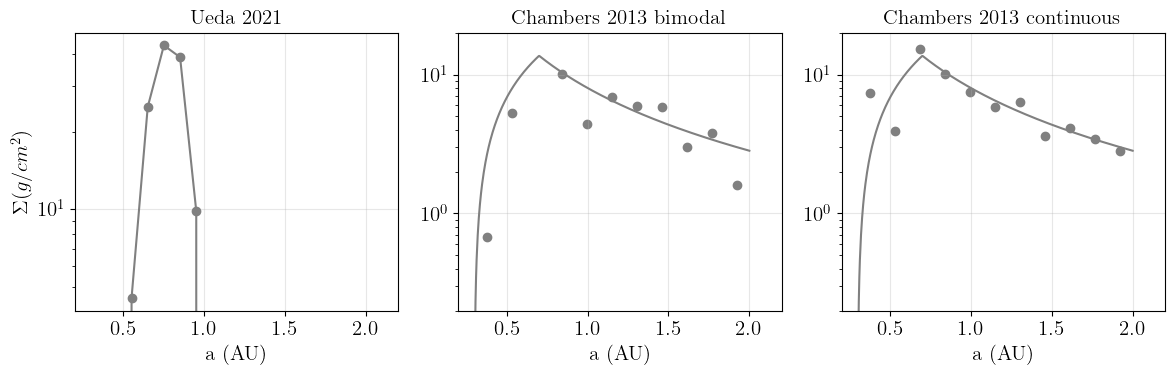

In [67]:
plt.figure(figsize=(12,4))


plt.subplot(1,3,1)
plt.plot(centers_ueda, sigmas_from_a_ueda, marker='o', color = 'gray')
plt.grid('True', alpha = 0.3)
plt.yscale('log')
plt.xlabel('a (AU)')
plt.ylabel(r'$\Sigma (g/cm^2)$')
plt.xlim(0.2, 2.2)
plt.title('Ueda 2021')


plt.subplot(1,3,2)
plt.scatter(cents_bi, sigma_bi, marker='o', color = 'gray')
plt.plot(a, Sig, color = 'gray')
plt.grid('True', alpha = 0.3)
plt.yscale('log')
plt.xlabel('a (AU)')
plt.xlim(0.2, 2.2)
plt.ylim(0.2,20)
plt.title("Chambers 2013 bimodal")


plt.subplot(1,3,3)
plt.scatter(cents_cont, sigma_cont, marker='o', color = 'gray')
plt.plot(a, Sig, color = 'gray')
plt.grid('True', alpha = 0.3)
plt.yscale('log')
plt.xlabel('a (AU)')
plt.xlim(0.2, 2.2)
plt.ylim(0.2,20)
plt.title('Chambers 2013 continuous')

plt.tight_layout()

plt.savefig('sigmas_talk.png', dpi=300)
plt.show()